In [1]:
import os
from pathlib import Path
# Simpan cache dataset di folder proyek , sebelum mengimpor TensorFlow .
os . environ [" KERAS_HOME "] = str( Path . cwd () / ". tools " / " keras ")
import numpy as np
import matplotlib . pyplot as plt
import tensorflow as tf
from sklearn . model_selection import train_test_split
from sklearn . metrics import classification_report , ConfusionMatrixDisplay
tf . keras . utils . set_random_seed (42)
print (" TensorFlow :", tf . __version__ )
EPOCHS = 5
BATCH_SIZE = 128

 TensorFlow : 2.21.0


In [3]:
gambar = tf.constant([[[[1.], [2.], [3.]],
                       [[4.], [5.], [6.]],
                       [[7.], [8.], [9.]]]])

kernel = tf.reshape(
    tf.constant([1., 0., 0., -1.]),
    (2, 2, 1, 1)
)
hasil = tf.nn.conv2d(
    gambar,
    kernel,
    strides=1,
    padding="VALID"
)
print("Input:\n", gambar.numpy()[0, :, :, 0])
print("Cross-correlation:\n", hasil.numpy()[0, :, :, 0])
assert np.allclose(hasil.numpy(), -4)

Input:
 [[1. 2. 3.]
 [4. 5. 6.]
 [7. 8. 9.]]
Cross-correlation:
 [[-4. -4.]
 [-4. -4.]]


In [5]:
contoh = tf.zeros((1, 28, 28, 1))
for padding, stride in [("valid", 1), ("same", 1), ("same", 2)]:
    layer = tf.keras.layers.Conv2D(
        4,
        3,
        padding=padding,
        strides=stride
    )
    print(
        f"padding={padding}, stride={stride}:",
        layer(contoh).shape
    )

padding=valid, stride=1: (1, 26, 26, 4)
padding=same, stride=1: (1, 28, 28, 4)
padding=same, stride=2: (1, 14, 14, 4)


In [7]:
contoh_rgb = tf.zeros((1, 28, 28, 3))
conv_rgb = tf.keras.layers.Conv2D(
    8,
    3,
    padding="same"
)
print(
    "Input RGB:",
    contoh_rgb.shape,
    "Output:",
    conv_rgb(contoh_rgb).shape
)
print(
    "Parameter:",
    conv_rgb.count_params(),
    "= (3 * 3 * 3 + 1) * 8"
)

Input RGB: (1, 28, 28, 3) Output: (1, 28, 28, 8)
Parameter: 224 = (3 * 3 * 3 + 1) * 8


In [8]:
nilai = tf . reshape (
tf . range (1 , 17 , dtype = tf . float32 ) ,
(1 , 4 , 4 , 1)
)
print (" Input :\n", nilai . numpy () [0 , : , : , 0])
print (
" Max pooling :\n",
tf . keras . layers . MaxPooling2D (2) ( nilai ) . numpy () [0 , : , : , 0]
)
print (
" Average pooling :\n",
tf . keras . layers . AveragePooling2D (2) ( nilai ) . numpy () [0 , : , :, 0]
)

 Input :
 [[ 1.  2.  3.  4.]
 [ 5.  6.  7.  8.]
 [ 9. 10. 11. 12.]
 [13. 14. 15. 16.]]
 Max pooling :
 [[ 6.  8.]
 [14. 16.]]
 Average pooling :
 [[ 3.5  5.5]
 [11.5 13.5]]


In [10]:
(x_pool, y_pool), (x_test, y_test) = \
    tf.keras.datasets.fashion_mnist.load_data()
nama_kelas = [
    "T-shirt /top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]
x_train, x_val, y_train, y_val = train_test_split(
    x_pool,
    y_pool,
    train_size=12000,
    test_size=3000,
    stratify=y_pool,
    random_state=42
)
x_train = x_train.astype("float32")[..., np.newaxis] / 255.0
x_val = x_val.astype("float32")[..., np.newaxis] / 255.0
x_test = x_test.astype("float32")[..., np.newaxis] / 255.0
print(
    "Train:",
    x_train.shape,
    "Validation:",
    x_val.shape,
    "Test:",
    x_test.shape
)

Train: (12000, 28, 28, 1) Validation: (3000, 28, 28, 1) Test: (10000, 28, 28, 1)


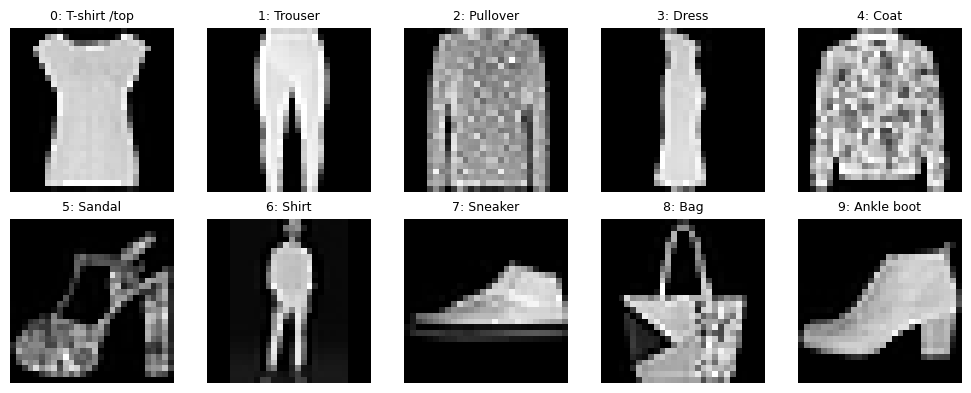

In [12]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for kelas, ax in enumerate(axes.flat):
    idx = np.flatnonzero(y_train == kelas)[0]
    ax.imshow(
        x_train[idx, :, :, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )
    ax.set_title(
        f"{kelas}: {nama_kelas[kelas]}",
        fontsize=9
    )
    ax.axis("off")
plt.tight_layout()
plt.show()

In [14]:
tf.keras.utils.set_random_seed(42)
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(
        8,
        3,
        padding="same",
        activation="relu",
        name="fitur_awal"
    ),
    tf.keras.layers.MaxPooling2D(2),
    tf.keras.layers.Conv2D(
        16,
        3,
        padding="same",
        activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
], name="cnn_sederhana")

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Model: "cnn_sederhana"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ fitur_awal (Conv2D)             │ (None, 28, 28, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 14, 14, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 7, 7, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,698 (104.29 KB)

 Trainable params: 26,698 (104.29 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
history = model . fit (
x_train ,
y_train ,
validation_data =( x_val , y_val ) ,
epochs = EPOCHS ,
batch_size = BATCH_SIZE ,
verbose =2
)

Epoch 1/5
94/94 - 4s - 48ms/step - accuracy: 0.5991 - loss: 1.1712 - val_accuracy: 0.7617 - val_loss: 0.6626
Epoch 2/5
94/94 - 3s - 29ms/step - accuracy: 0.7774 - loss: 0.5994 - val_accuracy: 0.7913 - val_loss: 0.5471
Epoch 3/5
94/94 - 5s - 55ms/step - accuracy: 0.8066 - loss: 0.5264 - val_accuracy: 0.8200 - val_loss: 0.4902
Epoch 4/5
94/94 - 3s - 35ms/step - accuracy: 0.8275 - loss: 0.4801 - val_accuracy: 0.8353 - val_loss: 0.4585
Epoch 5/5
94/94 - 3s - 28ms/step - accuracy: 0.8418 - loss: 0.4482 - val_accuracy: 0.8447 - val_loss: 0.4364


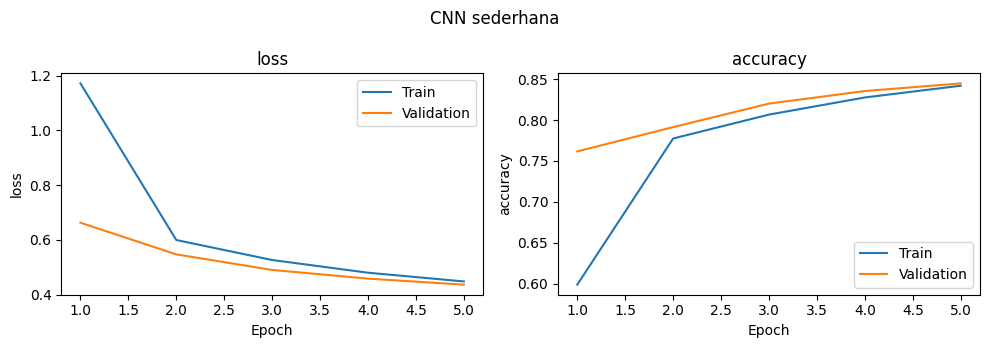

In [17]:
def plot_history(history, judul):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    epochs = range(1, len(history.history["loss"]) + 1)
    for ax, metric in zip(axes, ["loss", "accuracy"]):
        ax.plot(
            epochs,
            history.history[metric],
            label="Train"
        )
        ax.plot(
            epochs,
            history.history["val_" + metric],
            label="Validation"
        )
        ax.set(
            xlabel="Epoch",
            ylabel=metric,
            title=metric
        )
        ax.legend()
    fig.suptitle(judul)
    plt.tight_layout()
    plt.show()

plot_history(history, "CNN sederhana")

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_1']
Received: inputs=Tensor(shape=(1, 28, 28, 1))
  warnings.warn(msg)


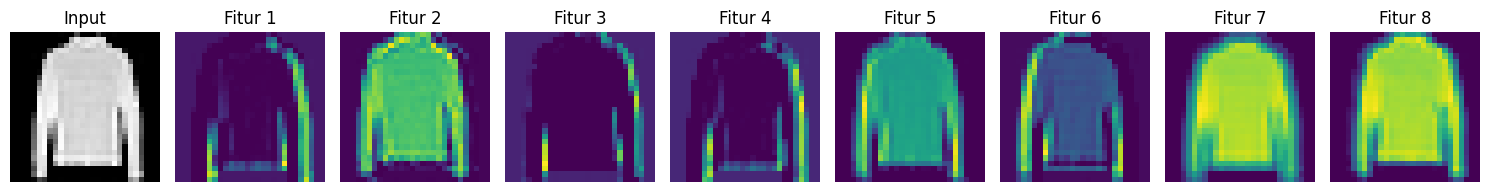

In [19]:
ekstraktor = tf.keras.Model(
    inputs=model.inputs,
    outputs=model.get_layer("fitur_awal").output
)

fitur = ekstraktor(
    x_val[:1],
    training=False
).numpy()[0]

fig, axes = plt.subplots(1, 9, figsize=(15, 2))
axes[0].imshow(x_val[0, :, :, 0], cmap="gray")
axes[0].set_title("Input")

for i in range(8):
    axes[i + 1].imshow(fitur[:, :, i], cmap="viridis")
    axes[i + 1].set_title(f"Fitur {i + 1}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Test loss: 0.4561 | Test accuracy: 83.61%


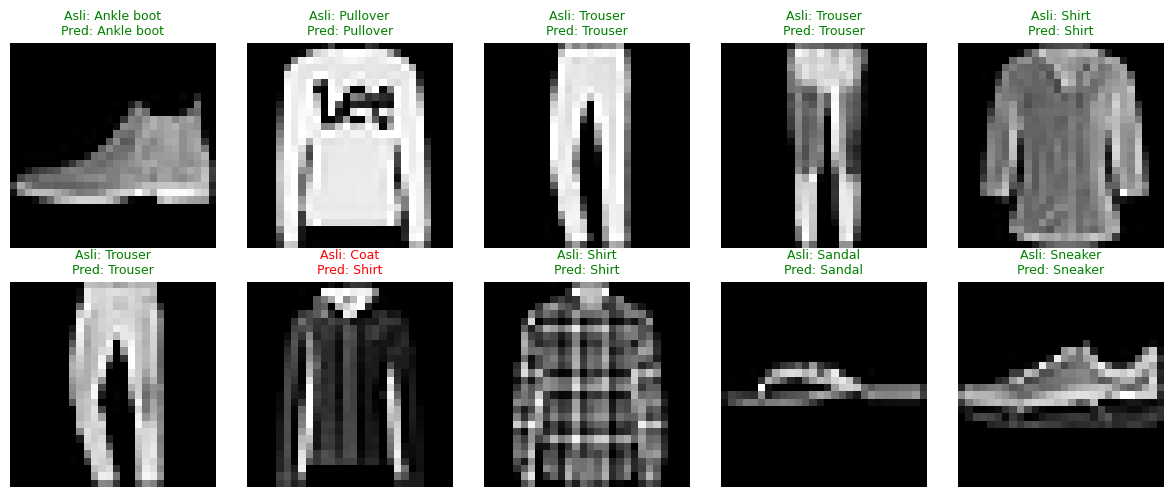

In [21]:
test_loss, test_acc = model.evaluate(
    x_test,
    y_test,
    verbose=0
)
print(
    f"Test loss: {test_loss:.4f} | "
    f"Test accuracy: {test_acc:.2%}"
)
prob = model.predict(x_test[:10], verbose=0)
pred = prob.argmax(axis=1)
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i, :, :, 0], cmap="gray")
    ax.set_title(
        f"Asli: {nama_kelas[y_test[i]]}\n"
        f"Pred: {nama_kelas[pred[i]]}",
        color="green" if pred[i] == y_test[i] else "red",
        fontsize=9
    )
    ax.axis("off")
plt.tight_layout()
plt.show()